<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/05_Correlation_and_Lag_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Correlation and Lag Analysis**

## 1. Overview

This notebook looks at whether changes in petrol and diesel prices are related to changes in food prices, and whether food prices react with a delay (a time lag).

We compare fuel and food price changes at lags from 0 to 18 months, using both monthly changes and year-on-year changes. We then use a simple regression at the strongest lag to estimate the size of the relationship.

This only shows association, not cause. Other factors like energy costs, wages and the euro also changed during the same period.

Data: `02_trend_analysis_output.csv` from Notebook 02 (CSO Ireland, CPM24, index December 2023 = 100).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# team colour scheme (same as the other notebooks)
colours = {
    "Petrol": "#1F77B4",
    "Diesel": "#C26A1C",
    "Food": "#2CA02C"
}

# source line added to every chart
source_text = "Source: CSO Ireland, CPM24"

# save charts to the repo's images/ folder (works from notebooks/ in VS Code or from the repo root)
IMG_DIR = "../images" if os.path.basename(os.getcwd()) == "notebooks" else "images"
os.makedirs(IMG_DIR, exist_ok=True)

data_url = "https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/main/data/02_trend_analysis_output.csv"

df = pd.read_csv(data_url)

df.head()

,Month_DT,Diesel,Grocery_CPI,Petrol,Petrol_3M_Avg,Petrol_12M_Avg,Diesel_3M_Avg,Diesel_12M_Avg,CPI_3M_Avg,CPI_12M_Avg,Petrol_YoY_Pct,Diesel_YoY_Pct,CPI_YoY_Pct,CPI_Trend,CPI_Seasonal,CPI_Residual
0,2016-01-01,65.0,90.7,72.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.246493,NaN
1,2016-02-01,61.1,90.0,70.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.246493,NaN
2,2016-03-01,61.9,90.3,70.0,71.1,NaN,62.666667,NaN,90.333333,NaN,NaN,NaN,NaN,NaN,-0.037743,NaN
3,2016-04-01,64.2,90.0,73.1,71.2,NaN,62.400000,NaN,90.100000,NaN,NaN,NaN,NaN,NaN,0.101146,NaN
4,2016-05-01,65.3,90.0,74.7,72.6,NaN,63.800000,NaN,90.100000,NaN,NaN,NaN,NaN,NaN,0.237257,NaN


In [2]:
df.columns.tolist()

['Month_DT',
 'Diesel',
 'Grocery_CPI',
 'Petrol',
 'Petrol_3M_Avg',
 'Petrol_12M_Avg',
 'Diesel_3M_Avg',
 'Diesel_12M_Avg',
 'CPI_3M_Avg',
 'CPI_12M_Avg',
 'Petrol_YoY_Pct',
 'Diesel_YoY_Pct',
 'CPI_YoY_Pct',
 'CPI_Trend',
 'CPI_Seasonal',
 'CPI_Residual']

## 2. Preparing the Data

We calculate the monthly percentage changes for diesel, petrol and grocery CPI so they can be compared consistently.

The year-on-year changes for petrol, diesel and grocery CPI come from Notebook 02 (change compared with the same month one year earlier).

We use changes instead of the index values, because all three indices rise over time. Two rising lines will always look related, even if they are not.

In [3]:
# convert the date column
df["Month_DT"] = pd.to_datetime(df["Month_DT"])

# calculate monthly percentage changes
df["Diesel_change"] = df["Diesel"].pct_change() * 100
df["Petrol_change"] = df["Petrol"].pct_change() * 100
df["Grocery_change"] = df["Grocery_CPI"].pct_change() * 100

# check the new columns
df[["Month_DT", "Diesel_change", "Petrol_change", "Grocery_change",
    "Diesel_YoY_Pct", "Petrol_YoY_Pct", "CPI_YoY_Pct"]].tail()

,Month_DT,Diesel_change,Petrol_change,Grocery_change,Diesel_YoY_Pct,Petrol_YoY_Pct,CPI_YoY_Pct
124,2026-05-01,-8.082409,-1.973094,0.093897,19.958635,10.070493,1.330798
125,2026-06-01,-5.517241,-1.097896,-0.375235,13.929314,9.081736,0.568182
126,2026-07-01,-6.386861,-4.070305,0.188324,3.427419,2.979146,0.662252
127,2026-08-01,11.013645,5.400193,-0.093985,15.050505,8.864542,0.094162
128,2026-09-01,5.355575,4.757548,0.094073,21.951220,14.043825,0.377358


## 3. Monthly Changes at Different Lags

We compare grocery CPI changes with fuel price changes from 0 to 18 months earlier. A lag of 3 means we compare food prices this month with fuel prices 3 months before.

In [4]:
# lags from 0 to 18 months
lags = range(0, 19)

monthly_results = []

for lag in lags:
    monthly_results.append({
        "Lag_Months": lag,
        "Diesel_Correlation": df["Grocery_change"].corr(df["Diesel_change"].shift(lag)),
        "Petrol_Correlation": df["Grocery_change"].corr(df["Petrol_change"].shift(lag))
    })

monthly_results = pd.DataFrame(monthly_results).round(3)
monthly_results

,Lag_Months,Diesel_Correlation,Petrol_Correlation
0,0,0.042,0.097
1,1,0.098,0.113
2,2,-0.027,-0.090
3,3,0.046,-0.053
4,4,0.115,0.064
5,5,0.053,0.002
6,6,0.056,0.031
7,7,0.144,0.089
8,8,0.225,0.222
9,9,0.209,0.212


All the monthly correlations are weak (below 0.25 at every lag). Monthly price changes are very noisy, so it is hard to see any clear pattern month to month. Because the values are so small, we do not pick a lag from this table.

## 4. Year-on-Year Changes at Different Lags

Year-on-year changes compare each month with the same month one year earlier. This removes seasonal patterns and short-term noise, so slower movements are easier to see.

In [5]:
yoy_results = []

for lag in lags:
    yoy_results.append({
        "Lag_Months": lag,
        "Diesel_YoY_Correlation": df["CPI_YoY_Pct"].corr(df["Diesel_YoY_Pct"].shift(lag)),
        "Petrol_YoY_Correlation": df["CPI_YoY_Pct"].corr(df["Petrol_YoY_Pct"].shift(lag))
    })

yoy_results = pd.DataFrame(yoy_results).round(3)
yoy_results

,Lag_Months,Diesel_YoY_Correlation,Petrol_YoY_Correlation
0,0,-0.019,-0.111
1,1,0.060,-0.046
2,2,0.139,0.021
3,3,0.220,0.096
4,4,0.297,0.176
5,5,0.373,0.259
6,6,0.454,0.346
7,7,0.518,0.425
8,8,0.565,0.489
9,9,0.597,0.537


With no lag, the year-on-year correlation is close to zero. It then increases as the lag gets longer and reaches about 0.6 when fuel leads food by 9–12 months, before it starts to drop again. The pattern is very similar for diesel and petrol.

## 5. Correlation vs Lag Chart

This chart shows the year-on-year correlation at each lag, so we can see where it is strongest.

Strongest diesel lag: 10 months, r = 0.614


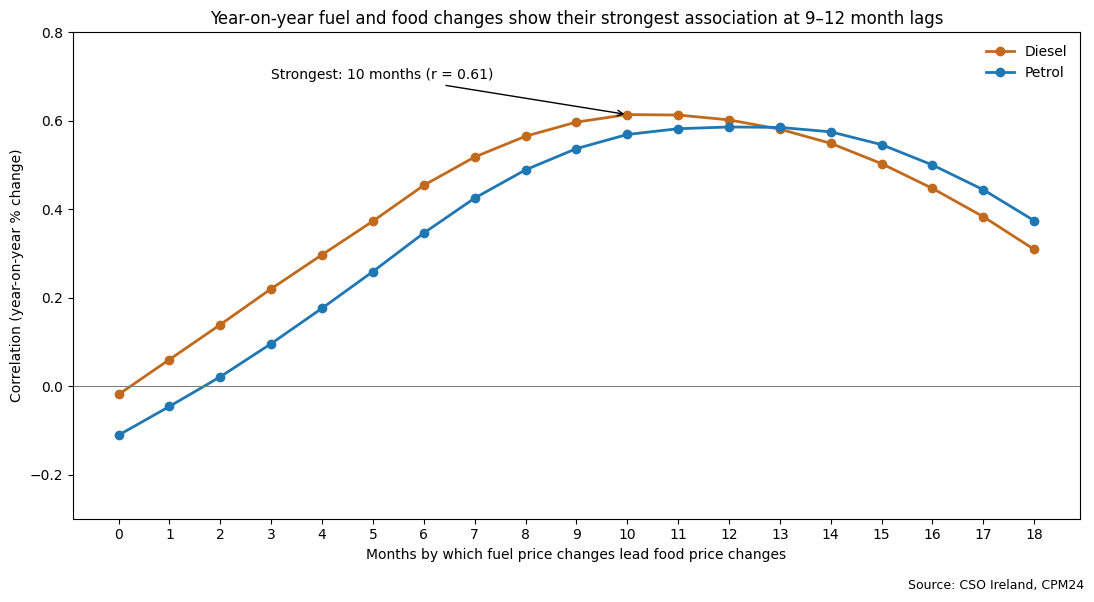

In [6]:
# find the lag with the highest diesel correlation
best_lag = int(yoy_results.loc[yoy_results["Diesel_YoY_Correlation"].idxmax(), "Lag_Months"])
best_corr = yoy_results.loc[best_lag, "Diesel_YoY_Correlation"]
print("Strongest diesel lag:", best_lag, "months, r =", best_corr)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(yoy_results["Lag_Months"], yoy_results["Diesel_YoY_Correlation"],
        marker="o", color=colours["Diesel"], linewidth=2, label="Diesel")
ax.plot(yoy_results["Lag_Months"], yoy_results["Petrol_YoY_Correlation"],
        marker="o", color=colours["Petrol"], linewidth=2, label="Petrol")

ax.axhline(0, color="grey", linewidth=0.8)

# point to the strongest diesel lag
ax.annotate(f"Strongest: {best_lag} months (r = {best_corr:.2f})",
            xy=(best_lag, best_corr), xytext=(best_lag - 7, best_corr + 0.08),
            arrowprops=dict(arrowstyle="->"))

ax.set_title("Year-on-year fuel and food changes show their strongest association at 9–12 month lags")
ax.set_xlabel("Months by which fuel price changes lead food price changes")
ax.set_ylabel("Correlation (year-on-year % change)")
ax.set_xticks(list(lags))
ax.set_ylim(-0.3, 0.8)
ax.legend(frameon=False)

plt.figtext(0.99, 0.01, source_text, ha="right", fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f"{IMG_DIR}/correlation_vs_lag_fuel_and_food.png", dpi=300, bbox_inches="tight")
plt.show()

The correlation is strongest at 10 months for diesel (r = 0.61) and at 12 months for petrol (r = 0.59). The values between 9 and 12 months are almost the same, so it is better to say food prices tend to follow fuel prices by about 9–12 months, rather than an exact number of months.

## 6. Linear Regression

We use a simple linear regression on the year-on-year changes at the strongest lag. The slope tells us how much food inflation changes, on average, when fuel inflation is 1 percentage point higher.

We do not use a p-value here. Neighbouring year-on-year values share 11 of their 12 months, so they are not independent, and a normal p-value would look much more certain than it really is.

In [7]:
regression_results = []

for fuel in ["Diesel", "Petrol"]:
    # strongest lag for this fuel
    fuel_lag = int(yoy_results.loc[yoy_results[f"{fuel}_YoY_Correlation"].idxmax(), "Lag_Months"])

    # food change this month and fuel change fuel_lag months earlier
    data = pd.DataFrame({
        "fuel_lagged": df[f"{fuel}_YoY_Pct"].shift(fuel_lag),
        "food": df["CPI_YoY_Pct"]
    }).dropna()

    # fit a straight line: food = slope * fuel + intercept
    slope, intercept = np.polyfit(data["fuel_lagged"], data["food"], 1)
    r = data["fuel_lagged"].corr(data["food"])

    regression_results.append({
        "Fuel": fuel,
        "Lag_Months": fuel_lag,
        "Months_Used": len(data),
        "Slope": slope,
        "Intercept": intercept,
        "R_squared": r ** 2
    })

regression_results = pd.DataFrame(regression_results).round(3)
regression_results

,Fuel,Lag_Months,Months_Used,Slope,Intercept,R_squared
0,Diesel,10,107,0.173,1.259,0.377
1,Petrol,12,105,0.209,1.420,0.343


For diesel, the slope is about 0.17. In simple terms, when diesel's year-on-year price change was 10 percentage points higher, food's year-on-year price change tended to be about 1.7 percentage points higher, 10 months later. The R-squared of 0.38 means the model accounts for about 38% of the variation in food inflation, so most of the variation is related to other factors. Petrol gives a similar result (slope 0.21 at 12 months, R-squared 0.34).

## 7. Checking Different Time Periods

The 2021–2023 period had very large fuel and food price rises. We check whether the 9–12 month result is mainly driven by this period by repeating the year-on-year diesel correlation for different time periods.

In [8]:
# time periods to compare (based on the food month)
periods = {
    "All months": df["Month_DT"].notna(),
    "2016–2020 only": df["Month_DT"] < "2021-01-01",
    "2021–2023 only": (df["Month_DT"] >= "2021-01-01") & (df["Month_DT"] < "2024-01-01"),
    "Without 2021–2023": (df["Month_DT"] < "2021-01-01") | (df["Month_DT"] >= "2024-01-01")
}

period_results = []

for name, mask in periods.items():
    row = {"Period": name}
    for lag in [0, 3, 6, 9, 10, 12]:
        row[f"Lag_{lag}"] = df.loc[mask, "CPI_YoY_Pct"].corr(df["Diesel_YoY_Pct"].shift(lag)[mask])
    period_results.append(row)

period_results = pd.DataFrame(period_results).set_index("Period").round(2)
period_results

,Lag_0,Lag_3,Lag_6,Lag_9,Lag_10,Lag_12
Period,,,,,,
All months,-0.02,0.22,0.45,0.60,0.61,0.60
2016–2020 only,-0.50,-0.31,0.13,0.41,0.32,0.01
2021–2023 only,-0.25,0.23,0.62,0.91,0.95,0.87
Without 2021–2023,-0.11,-0.26,-0.36,-0.42,-0.41,-0.31


The result changes a lot depending on the time period. In 2021–2023 the correlation at 9–10 months is above 0.9, but when these years are left out, it becomes negative (about −0.4). In 2016–2020 alone it is weaker (about 0.3–0.4 at 9–10 months) and based on only 3–4 years of data.

This means the 9–12 month pattern mostly comes from the 2021–2023 period, when fuel prices rose first and food prices rose later. It is not a stable pattern that we can see in every period.

## 8. Conclusion and Limitations

Monthly fuel and food price changes are only weakly related at any lag. Year-on-year changes show a clearer pattern: food price changes tend to follow diesel and petrol price changes by about 9–12 months (r ≈ 0.6). However, this pattern mostly comes from the 2021–2023 inflation period and does not appear when those years are left out.

Limitations:
- Neighbouring year-on-year values overlap (they share 11 of 12 months), so a correlation of 0.6 looks more certain than it is.
- The lag was chosen because it gave the highest correlation, so the result may look stronger than it would on new data.
- Other costs like energy for processing, wages and the euro also rose during the same period, so this does not show that fuel prices caused the food price rises.
- This uses national CPI index values, so it does not show which food products react most.